# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import AveragePooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


True

# Importamos los datos

In [4]:
path = '../../../data/clean/Campo 100 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')
campvectrain = np.transpose(campvectrain, (0,2,3,1))

In [6]:
np.shape(campvectrain)

(7000, 100, 100, 2)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')
campvectest = np.transpose(campvectest, (0,2,3,1))

In [10]:
np.shape(campvectest)

(2000, 100, 100, 2)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(2000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')
campvecval = np.transpose(campvecval, (0,2,3,1))

In [14]:
np.shape(campvecval)

(1000, 100, 100, 2)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(1000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(100, 100, 2), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [20]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [21]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [22]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [23]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

In [39]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(scheduler)

def objective(trial):
    model = Sequential()
    n_conv_layers = trial.suggest_int("n_conv_layers", 1, 5)
    
    input_shape = (100, 100, 2)  # Tus dimensiones de entrada
    current_shape = (20,20,2)
    
    for i in range(n_conv_layers):
        num_filters = trial.suggest_int(f"num_filters_{i+1}", 8, 50)
        filter_size1 = trial.suggest_int(f"filter_size1_{i+1}", 2, 5)
        filter_size2 = trial.suggest_int(f"filter_size2_{i+1}", 2, 5)
        activation = trial.suggest_categorical(f"activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"kernel_regularizer_{i+1}", ['l1', 'l2'])
        
        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)
            
            
        if (current_shape[0] - filter_size1 + 1 > 0) and (current_shape[1] - filter_size2 + 1 > 0):
            if i == 0:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, input_shape=input_shape, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            else:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            
            current_shape = (current_shape[0] - filter_size1 + 1, current_shape[1] - filter_size2 + 1, num_filters)
            
        # Decide si agregar una capa de MaxPooling después de esta capa convolucional
        add_maxpooling = trial.suggest_categorical(f"add_maxpooling_after_conv_{i+1}", [True, False])
        if add_maxpooling:
            if current_shape[0] >= 2 and current_shape[1] >= 2:  # Asegurarse de que ambas dimensiones son suficientes para MaxPooling
                model.add(MaxPooling2D(pool_size=(2, 2)))
                current_shape = (current_shape[0] // 2, current_shape[1] // 2, current_shape[2])
        
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 4)
    
    for i in range(n_dense_layers):
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
    
        # Decide si agregar una capa de BatchNormalization después de esta capa densa
#        add_batchnorm = trial.suggest_categorical(f"add_batchnorm_after_dense_{i+1}", [True, False])
#        if add_batchnorm:
#            model.add(BatchNormalization())    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))
    model.add(GlobalAveragePooling2D())

        
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
        
    model.compile(optimizer=optimizer, loss= 'mean_squared_error', metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=30,  
        callbacks=[reduce_lr, early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=100)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

[I 2023-11-01 09:21:53,782] A new study created in memory with name: no-name-2474928c-b5af-4590-8f38-7afc6015d73b


Epoch 1/30
70/70 [==============================] - 7s 93ms/step - loss: 8.4831 - a_1: 2.7659 - a_2: 2.7613 - b_1: 2.6364 - b_2: 2.7484 - d_1: 1.4210 - d_2: 1.4051 - n: 1.5976 - mean_metric: 0.5055 - val_loss: 7.7726 - val_a_1: 2.7140 - val_a_2: 2.7494 - val_b_1: 2.5757 - val_b_2: 2.7857 - val_d_1: 0.8468 - val_d_2: 0.8796 - val_n: 1.5831 - val_mean_metric: 0.4676 - lr: 0.0010
Epoch 2/30
70/70 [==============================] - 6s 89ms/step - loss: 7.5604 - a_1: 2.7688 - a_2: 2.7520 - b_1: 2.5681 - b_2: 2.7408 - d_1: 0.8243 - d_2: 0.8185 - n: 1.4857 - mean_metric: 0.4601 - val_loss: 7.4467 - val_a_1: 2.7085 - val_a_2: 2.7405 - val_b_1: 2.4142 - val_b_2: 2.7830 - val_d_1: 0.8076 - val_d_2: 0.8049 - val_n: 1.5869 - val_mean_metric: 0.4580 - lr: 0.0010
Epoch 3/30
70/70 [==============================] - 6s 89ms/step - loss: 7.2717 - a_1: 2.7634 - a_2: 2.7510 - b_1: 2.3711 - b_2: 2.7423 - d_1: 0.7891 - d_2: 0.8001 - n: 1.4818 - mean_metric: 0.4516 - val_loss: 7.3475 - val_a_1: 2.7229 - val

Epoch 23/30
70/70 [==============================] - 6s 90ms/step - loss: 6.0253 - a_1: 2.7158 - a_2: 2.7193 - b_1: 1.6509 - b_2: 2.7368 - d_1: 0.4552 - d_2: 0.5016 - n: 1.4516 - mean_metric: 0.4032 - val_loss: 5.9240 - val_a_1: 2.6375 - val_a_2: 2.6861 - val_b_1: 1.5740 - val_b_2: 2.7828 - val_d_1: 0.4162 - val_d_2: 0.5603 - val_n: 1.4471 - val_mean_metric: 0.4005 - lr: 0.0010
Epoch 24/30
70/70 [==============================] - 6s 90ms/step - loss: 6.1023 - a_1: 2.7156 - a_2: 2.7183 - b_1: 1.7247 - b_2: 2.7360 - d_1: 0.4968 - d_2: 0.5703 - n: 1.4549 - mean_metric: 0.4093 - val_loss: 5.9062 - val_a_1: 2.6387 - val_a_2: 2.6842 - val_b_1: 1.5700 - val_b_2: 2.7822 - val_d_1: 0.4464 - val_d_2: 0.4851 - val_n: 1.4474 - val_mean_metric: 0.3988 - lr: 0.0010
Epoch 25/30
70/70 [==============================] - 6s 90ms/step - loss: 6.0146 - a_1: 2.7138 - a_2: 2.7160 - b_1: 1.6697 - b_2: 2.7357 - d_1: 0.4278 - d_2: 0.5206 - n: 1.4535 - mean_metric: 0.4035 - val_loss: 6.0349 - val_a_1: 2.6454 - 

[I 2023-11-01 09:25:03,899] Trial 0 finished with value: 0.39969876408576965 and parameters: {'n_conv_layers': 5, 'num_filters_1': 43, 'filter_size1_1': 2, 'filter_size2_1': 4, 'activation_1': 'sigmoid', 'kernel_initializer_1': 'glorot_uniform', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': False, 'num_filters_2': 16, 'filter_size1_2': 4, 'filter_size2_2': 4, 'activation_2': 'tanh', 'kernel_initializer_2': 'HeNormal', 'kernel_regularizer_2': 'l1', 'add_maxpooling_after_conv_2': False, 'num_filters_3': 41, 'filter_size1_3': 2, 'filter_size2_3': 2, 'activation_3': 'relu', 'kernel_initializer_3': 'glorot_uniform', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': True, 'num_filters_4': 9, 'filter_size1_4': 2, 'filter_size2_4': 2, 'activation_4': 'relu', 'kernel_initializer_4': 'glorot_uniform', 'kernel_regularizer_4': 'l1', 'add_maxpooling_after_conv_4': True, 'num_filters_5': 41, 'filter_size1_5': 5, 'filter_size2_5': 3, 'activation_5': 'relu', 'kernel_initializ

Epoch 1/30
70/70 [==============================] - 7s 83ms/step - loss: 11.2635 - a_1: 2.7764 - a_2: 2.7516 - b_1: 2.7642 - b_2: 2.7526 - d_1: 2.7277 - d_2: 2.7929 - n: 1.7320 - mean_metric: 0.6031 - val_loss: 10.2314 - val_a_1: 2.6785 - val_a_2: 2.7295 - val_b_1: 2.6492 - val_b_2: 2.7782 - val_d_1: 2.3380 - val_d_2: 2.7200 - val_n: 1.4679 - val_mean_metric: 0.5745 - lr: 0.0010
Epoch 2/30
70/70 [==============================] - 6s 79ms/step - loss: 9.6467 - a_1: 2.7648 - a_2: 2.7514 - b_1: 2.7286 - b_2: 2.7408 - d_1: 1.6568 - d_2: 2.5741 - n: 1.4871 - mean_metric: 0.5507 - val_loss: 8.8448 - val_a_1: 2.6852 - val_a_2: 2.7291 - val_b_1: 2.6183 - val_b_2: 2.7771 - val_d_1: 1.4304 - val_d_2: 2.0261 - val_n: 1.4693 - val_mean_metric: 0.5207 - lr: 0.0010
Epoch 3/30
70/70 [==============================] - 6s 79ms/step - loss: 8.4781 - a_1: 2.7641 - a_2: 2.7489 - b_1: 2.5963 - b_2: 2.7385 - d_1: 1.3554 - d_2: 1.5308 - n: 1.4889 - mean_metric: 0.5019 - val_loss: 8.1036 - val_a_1: 2.6836 - v

Epoch 23/30
70/70 [==============================] - 6s 79ms/step - loss: 6.4587 - a_1: 2.7572 - a_2: 2.7503 - b_1: 1.9977 - b_2: 2.7353 - d_1: 0.7464 - d_2: 0.6532 - n: 1.4659 - mean_metric: 0.4321 - val_loss: 6.3323 - val_a_1: 2.6741 - val_a_2: 2.7302 - val_b_1: 1.8972 - val_b_2: 2.7787 - val_d_1: 0.6781 - val_d_2: 0.7711 - val_n: 1.4544 - val_mean_metric: 0.4296 - lr: 0.0010
Epoch 24/30
70/70 [==============================] - 6s 79ms/step - loss: 6.3779 - a_1: 2.7583 - a_2: 2.7512 - b_1: 1.9349 - b_2: 2.7355 - d_1: 0.7054 - d_2: 0.6326 - n: 1.4624 - mean_metric: 0.4280 - val_loss: 6.2149 - val_a_1: 2.6734 - val_a_2: 2.7295 - val_b_1: 1.8448 - val_b_2: 2.7799 - val_d_1: 0.6458 - val_d_2: 0.5386 - val_n: 1.4513 - val_mean_metric: 0.4190 - lr: 0.0010
Epoch 25/30
70/70 [==============================] - 6s 79ms/step - loss: 6.3059 - a_1: 2.7580 - a_2: 2.7513 - b_1: 1.8741 - b_2: 2.7345 - d_1: 0.6673 - d_2: 0.6039 - n: 1.4600 - mean_metric: 0.4236 - val_loss: 6.1853 - val_a_1: 2.6782 - 

... (126 outputs left out)

Epoch 1/30
70/70 [==============================] - 13s 173ms/step - loss: 7.8639 - a_1: 2.7653 - a_2: 2.7629 - b_1: 2.6374 - b_2: 2.7521 - d_1: 1.1286 - d_2: 1.2124 - n: 1.5597 - mean_metric: 0.4884 - val_loss: 7.1518 - val_a_1: 2.6919 - val_a_2: 2.7387 - val_b_1: 2.5689 - val_b_2: 2.7890 - val_d_1: 0.8889 - val_d_2: 0.7641 - val_n: 1.4713 - val_mean_metric: 0.4603 - lr: 0.0010
Epoch 2/30
70/70 [==============================] - 12s 170ms/step - loss: 7.0716 - a_1: 2.7701 - a_2: 2.7567 - b_1: 2.6130 - b_2: 2.7431 - d_1: 0.8022 - d_2: 0.7760 - n: 1.4874 - mean_metric: 0.4598 - val_loss: 6.7953 - val_a_1: 2.6834 - val_a_2: 2.7245 - val_b_1: 2.4841 - val_b_2: 2.7841 - val_d_1: 0.8661 - val_d_2: 0.6655 - val_n: 1.4687 - val_mean_metric: 0.4525 - lr: 0.0010
Epoch 3/30
70/70 [==============================] - 12s 170ms/step - loss: 6.7786 - a_1: 2.7674 - a_2: 2.7598 - b_1: 2.4324 - b_2: 2.7392 - d_1: 0.7955 - d_2: 0.7191 - n: 1.4836 - mean_metric: 0.4516 - val_loss: 6.6251 - val_a_1: 2.6727

[I 2023-11-01 11:37:19,192] Trial 47 finished with value: 0.3565963804721832 and parameters: {'n_conv_layers': 5, 'num_filters_1': 8, 'filter_size1_1': 5, 'filter_size2_1': 3, 'activation_1': 'sigmoid', 'kernel_initializer_1': 'glorot_uniform', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': False, 'num_filters_2': 35, 'filter_size1_2': 4, 'filter_size2_2': 5, 'activation_2': 'tanh', 'kernel_initializer_2': 'glorot_uniform', 'kernel_regularizer_2': 'l1', 'add_maxpooling_after_conv_2': False, 'num_filters_3': 48, 'filter_size1_3': 4, 'filter_size2_3': 3, 'activation_3': 'relu', 'kernel_initializer_3': 'random_normal', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': False, 'num_filters_4': 50, 'filter_size1_4': 4, 'filter_size2_4': 5, 'activation_4': 'relu', 'kernel_initializer_4': 'glorot_uniform', 'kernel_regularizer_4': 'l2', 'add_maxpooling_after_conv_4': True, 'num_filters_5': 36, 'filter_size1_5': 2, 'filter_size2_5': 4, 'activation_5': 'relu', 'kernel_ini

Epoch 1/30
70/70 [==============================] - 12s 167ms/step - loss: 8.7137 - a_1: 2.7722 - a_2: 2.7568 - b_1: 2.6481 - b_2: 2.7477 - d_1: 1.3060 - d_2: 1.2636 - n: 1.5320 - mean_metric: 0.4953 - val_loss: 7.9785 - val_a_1: 2.6901 - val_a_2: 2.7401 - val_b_1: 2.5724 - val_b_2: 2.7805 - val_d_1: 0.8683 - val_d_2: 0.8335 - val_n: 1.4654 - val_mean_metric: 0.4616 - lr: 0.0010
Epoch 2/30
70/70 [==============================] - 12s 165ms/step - loss: 7.8409 - a_1: 2.7619 - a_2: 2.7594 - b_1: 2.5180 - b_2: 2.7410 - d_1: 0.7874 - d_2: 0.8128 - n: 1.4841 - mean_metric: 0.4571 - val_loss: 7.5845 - val_a_1: 2.6850 - val_a_2: 2.7333 - val_b_1: 2.4318 - val_b_2: 2.7820 - val_d_1: 0.7177 - val_d_2: 0.7078 - val_n: 1.4644 - val_mean_metric: 0.4473 - lr: 0.0010
Epoch 3/30
70/70 [==============================] - 11s 163ms/step - loss: 7.4897 - a_1: 2.7598 - a_2: 2.7569 - b_1: 2.2819 - b_2: 2.7409 - d_1: 0.7985 - d_2: 0.7611 - n: 1.4729 - mean_metric: 0.4474 - val_loss: 7.5979 - val_a_1: 2.6845

[W 2023-11-01 13:30:57,753] Trial 48 failed with value None.


In [ ]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [28]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.regularizers import l1
from tensorflow.keras.initializers import HeNormal


model = Sequential()

# Primera capa convolucional con padding
model.add(Conv2D(50, (5, 5), activation='tanh', padding='same', input_shape=(None, None, 2), kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Segunda capa convolucional con padding
model.add(Conv2D(24, (5, 5), activation='tanh', padding='same', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Tercera capa convolucional con padding
model.add(Conv2D(11, (5, 5), activation='tanh', padding='same', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Cuarta capa convolucional con padding
model.add(Conv2D(50, (5, 5), activation='tanh', padding='same', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Pooling global
model.add(GlobalAveragePooling2D())

# Capas completamente conectadas
model.add(Dense(200, activation='tanh', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(100, activation='tanh', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(50, activation='relu', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(7, activation=custom_activation))

# Mostrar el resumen del modelo
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_14 (Conv2D)          (None, 18, 16, 15)        465       
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 9, 8, 15)         0         
 2D)                                                             
                                                                 
 conv2d_15 (Conv2D)          (None, 5, 5, 48)          14448     
                                                                 
 conv2d_16 (Conv2D)          (None, 2, 1, 39)          37479     
                                                                 
 flatten_1 (Flatten)         (None, 78)                0         
                                                                 
 dense_2 (Dense)             (None, 31)                2449      
                                                      

In [54]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Flatten, Dense, BatchNormalization, Dropout
from tensorflow.keras.regularizers import l1, l2
# Iniciar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(12, (5, 3), activation='tanh', input_shape = (None,None,2), kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Segunda capa convolucional
model.add(Conv2D(50, (4, 4), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Aplanar para capas densas
model.add(GlobalAveragePooling2D())

# Primera capa densa
model.add(Dense(30, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Añadir BatchNormalization
model.add(Dropout(0.16623681640801413))  # Añadir Dropout

# Segunda capa densa
model.add(Dense(61, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))
model.add(BatchNormalization())  # Añadir BatchNormalization

# Tercera capa densa
model.add(Dense(63, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Añadir BatchNormalization

model.add(Dense(7, activation=custom_activation))

# Resumen del modelo para verificar la arquitectura
model.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_37 (Conv2D)          (None, None, None, 12)    372       
                                                                 
 max_pooling2d_16 (MaxPoolin  (None, None, None, 12)   0         
 g2D)                                                            
                                                                 
 conv2d_38 (Conv2D)          (None, None, None, 50)    9650      
                                                                 
 max_pooling2d_17 (MaxPoolin  (None, None, None, 50)   0         
 g2D)                                                            
                                                                 
 global_average_pooling2d_5   (None, 50)               0         
 (GlobalAveragePooling2D)                                        
                                                     

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l1, l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(58, (4, 1), activation='relu', input_shape=(None, None, 2), kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Aplanar
model.add(GlobalAveragePooling2D())

# Primera capa densa
model.add(Dense(28, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Segunda capa densa
model.add(Dense(41, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Tercera capa densa
model.add(Dense(120, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Dropout
model.add(Dropout(0.3))

# Capa de salida (Asumiendo que custom_activation es 'relu' o alguna otra función de activación que ya tienes)
model.add(Dense(7, activation=custom_activation))

# Resumen del modelo para verificar la arquitectura
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, None, None, 58)    522       
                                                                 
 max_pooling2d_1 (MaxPooling  (None, None, None, 58)   0         
 2D)                                                             
                                                                 
 global_average_pooling2d_1   (None, 58)               0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dense_4 (Dense)             (None, 28)                1652      
                                                                 
 dense_5 (Dense)             (None, 41)                1189      
                                                                 
 dense_6 (Dense)             (None, 120)              

In [22]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.regularizers import l1, l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(56, (4, 5), activation='tanh',input_shape=(None, None, 2), kernel_initializer='random_normal', kernel_regularizer=l1()))
model.add(MaxPooling2D())  # MaxPooling

# Segunda capa convolucional
model.add(Conv2D(21, (4, 3), activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2()))
model.add(MaxPooling2D())  # MaxPooling

# Tercera capa convolucional
model.add(Conv2D(60, (4, 5), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1()))


# Aplanar para capas densas
#model.add(Flatten())

# Capa densa
model.add(Dense(110, activation='sigmoid', kernel_initializer='HeNormal', kernel_regularizer=l2()))

model.add(Dense(110, activation='sigmoid', kernel_initializer='HeNormal', kernel_regularizer=l2()))

model.add(Dense(7, activation=custom_activation))

model.add(GlobalAveragePooling2D())


# Resumen del modelo
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, None, None, 56)    2296      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, None, None, 56)   0         
 2D)                                                             
                                                                 
 conv2d_4 (Conv2D)           (None, None, None, 21)    14133     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, None, None, 21)   0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, None, None, 60)    25260     
                                                                 
 dense_2 (Dense)             (None, None, None, 110)  

In [32]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.regularizers import l1, l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(35, (5, 5), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001), input_shape=(None, None, 2)))
model.add(MaxPooling2D((2, 2)))

# Segunda capa convolucional
model.add(Conv2D(27, (3, 4), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D((2, 2)))

# Tercera capa convolucional
model.add(Conv2D(34, (2, 2), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))

# Cuarta capa convolucional
model.add(Conv2D(9, (4, 4), activation='sigmoid', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

# Quinta capa convolucional
model.add(Conv2D(49, (2, 2), activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))

# Aplanar para capas densas
model.add(GlobalAveragePooling2D())

# Primera capa densa
model.add(Dense(109, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())
model.add(Dropout(0.12842958290775042))

# Segunda capa densa
model.add(Dense(35, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())

# Tercera capa densa
model.add(Dense(80, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))

model.add(Dense(7, activation=custom_activation))

# Resumen del modelo
model.summary()


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_10 (Conv2D)          (None, None, None, 35)    1785      
                                                                 
 max_pooling2d_4 (MaxPooling  (None, None, None, 35)   0         
 2D)                                                             
                                                                 
 conv2d_11 (Conv2D)          (None, None, None, 27)    11367     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, None, None, 27)   0         
 2D)                                                             
                                                                 
 conv2d_12 (Conv2D)          (None, None, None, 34)    3706      
                                                                 
 conv2d_13 (Conv2D)          (None, None, None, 9)    

In [38]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.regularizers import l1, l2

# Iniciar el modelo
model = Sequential()

# Input shape (Asumo que es el mismo que antes: (50, 10, 2))

# Primera capa convolucional
model.add(Conv2D(16, (4, 5), activation='relu', input_shape=(None, None, 2), kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))

# Segunda capa convolucional
model.add(Conv2D(42, (2, 4), activation='tanh', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Tercera capa convolucional
model.add(Conv2D(51, (3, 4), activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Primera capa densa
model.add(Dense(108, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))

# Segunda capa densa
model.add(Dense(105, activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))


model.add(Dense(7, activation=custom_activation))

model.add(GlobalAveragePooling2D())


# Resumen del modelo para verificar la arquitectura
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_12 (Conv2D)          (None, None, None, 16)    656       
                                                                 
 conv2d_13 (Conv2D)          (None, None, None, 42)    5418      
                                                                 
 max_pooling2d_8 (MaxPooling  (None, None, None, 42)   0         
 2D)                                                             
                                                                 
 conv2d_14 (Conv2D)          (None, None, None, 51)    25755     
                                                                 
 max_pooling2d_9 (MaxPooling  (None, None, None, 51)   0         
 2D)                                                             
                                                                 
 dense_9 (Dense)             (None, None, None, 108)  

In [41]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(18, (5, 3), activation='sigmoid', kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001), input_shape=(None, None, 2)))
model.add(MaxPooling2D((2, 2)))

# Segunda capa convolucional
model.add(Conv2D(47, (3, 4), activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001)))

# Tercera capa convolucional
model.add(Conv2D(38, (5, 4), activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001)))

# Cuarta capa convolucional
model.add(Conv2D(50, (4, 5), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D((2, 2)))

# Quinta capa convolucional
model.add(Conv2D(22, (2, 5), activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D((2, 2)))


# Primera capa densa
model.add(Dense(79, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.21781610691210448))

# Segunda capa densa
model.add(Dense(89, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.28688773827478586))

model.add(Dense(7, activation=custom_activation))

model.add(GlobalAveragePooling2D())

# Resumen del modelo
model.summary()


Model: "sequential_65"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_174 (Conv2D)         (None, None, None, 18)    558       
                                                                 
 max_pooling2d_103 (MaxPooli  (None, None, None, 18)   0         
 ng2D)                                                           
                                                                 
 conv2d_175 (Conv2D)         (None, None, None, 47)    10199     
                                                                 
 conv2d_176 (Conv2D)         (None, None, None, 38)    35758     
                                                                 
 conv2d_177 (Conv2D)         (None, None, None, 50)    38050     
                                                                 
 max_pooling2d_104 (MaxPooli  (None, None, None, 50)   0         
 ng2D)                                               

In [30]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization, Dropout

def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    # Capa de atención
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(inputs, inputs)
    x = Dropout(dropout)(x)
    x = LayerNormalization(epsilon=1e-6)(x + inputs)

    # Feed forward network
    ff = Dense(ff_dim, activation="relu")(x)
    ff = Dropout(dropout)(ff)
    ff = Dense(inputs.shape[-1])(ff)
    x = LayerNormalization(epsilon=1e-6)(x + ff)
    return x

def build_transformer_model(input_shape, head_size, num_heads, ff_dim, num_transformer_blocks, mlp_units, dropout=0, mlp_dropout=0):
    inputs = Input(shape=input_shape)
    x = inputs
    
    for _ in range(num_transformer_blocks):
        x = transformer_encoder(x, head_size, num_heads, ff_dim, dropout)
    
    x = GlobalAveragePooling2D(data_format="channels_first")(x)
    for dim in mlp_units:
        x = Dense(dim, activation="relu")(x)
        x = Dropout(mlp_dropout)(x)
    outputs = Dense(7, activation=custom_activation)(x)
    return Model(inputs, outputs)


model = build_transformer_model(
    input_shape=(None, None, 2),
    head_size=256,
    num_heads=4,
    ff_dim=4,
    num_transformer_blocks=4,
    mlp_units=[128],
    mlp_dropout=0.4,
    dropout=0.25,
)



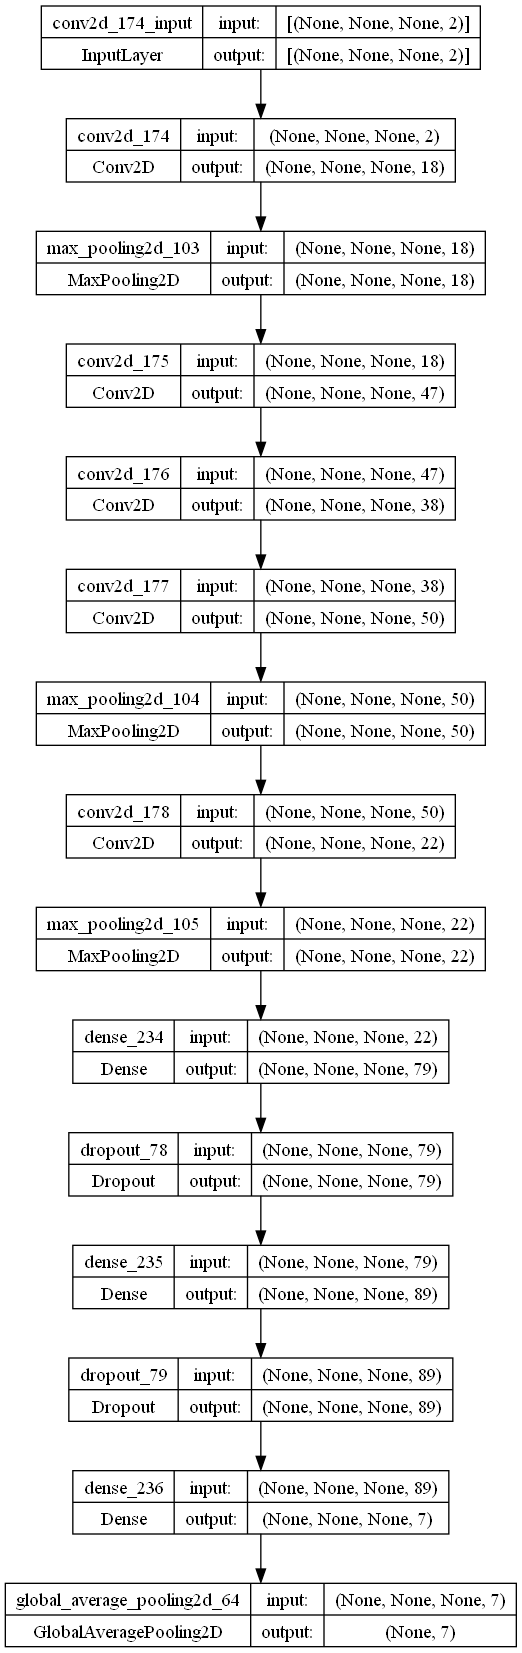

In [42]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [43]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [44]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [45]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [46]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [47]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 5s 68ms/step - loss: 7.3552 - a_1: 2.7855 - a_2: 2.7735 - b_1: 2.5727 - b_2: 2.7519 - d_1: 1.2227 - d_2: 1.2233 - n: 1.5236 - mean_metric: 0.4895 - val_loss: 6.6551 - val_a_1: 2.7008 - val_a_2: 2.7428 - val_b_1: 2.3685 - val_b_2: 2.8006 - val_d_1: 0.8411 - val_d_2: 0.8731 - val_n: 1.4892 - val_mean_metric: 0.4571 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 4s 64ms/step - loss: 6.3456 - a_1: 2.7646 - a_2: 2.7600 - b_1: 2.0235 - b_2: 2.7467 - d_1: 0.8132 - d_2: 0.7835 - n: 1.4721 - mean_metric: 0.4405 - val_loss: 5.9198 - val_a_1: 2.6802 - val_a_2: 2.7286 - val_b_1: 1.5222 - val_b_2: 2.8054 - val_d_1: 0.8050 - val_d_2: 0.6375 - val_n: 1.4810 - val_mean_metric: 0.4188 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 4s 64ms/step - loss: 5.9015 - a_1: 2.7505 - a_2: 2.7606 - b_1: 1.5575 - b_2: 2.7491 - d_1: 0.6333 - d_2: 0.6106 - n: 1.4640 - mean_metric: 0.4130 - val_loss: 5.8361 - val_a_1: 2.6655

70/70 [==============================] - 5s 65ms/step - loss: 3.2737 - a_1: 1.6788 - a_2: 1.5726 - b_1: 0.9911 - b_2: 2.7334 - d_1: 0.4036 - d_2: 0.3670 - n: 0.4684 - mean_metric: 0.2708 - val_loss: 3.4798 - val_a_1: 1.7251 - val_a_2: 1.5601 - val_b_1: 1.0456 - val_b_2: 2.7937 - val_d_1: 0.6267 - val_d_2: 0.7187 - val_n: 0.5442 - val_mean_metric: 0.2983 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 5s 66ms/step - loss: 3.2036 - a_1: 1.6447 - a_2: 1.5379 - b_1: 0.9681 - b_2: 2.7298 - d_1: 0.3628 - d_2: 0.3561 - n: 0.4543 - mean_metric: 0.2655 - val_loss: 3.2597 - val_a_1: 1.5810 - val_a_2: 1.5419 - val_b_1: 0.9421 - val_b_2: 2.7967 - val_d_1: 0.4310 - val_d_2: 0.3170 - val_n: 0.5012 - val_mean_metric: 0.2685 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 5s 65ms/step - loss: 3.1895 - a_1: 1.6397 - a_2: 1.5398 - b_1: 0.9642 - b_2: 2.7323 - d_1: 0.3416 - d_2: 0.3224 - n: 0.4571 - mean_metric: 0.2636 - val_loss: 3.3345 - val_a_1: 1.6246 - val_a_2:

70/70 [==============================] - 5s 65ms/step - loss: 2.9321 - a_1: 1.4830 - a_2: 1.4125 - b_1: 0.8734 - b_2: 2.7265 - d_1: 0.3297 - d_2: 0.3057 - n: 0.3609 - mean_metric: 0.2470 - val_loss: 3.0167 - val_a_1: 1.4832 - val_a_2: 1.4568 - val_b_1: 0.8719 - val_b_2: 2.7990 - val_d_1: 0.2716 - val_d_2: 0.2534 - val_n: 0.4060 - val_mean_metric: 0.2497 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.9749 - a_1: 1.5025 - a_2: 1.4464 - b_1: 0.8925 - b_2: 2.7273 - d_1: 0.3582 - d_2: 0.3461 - n: 0.3668 - mean_metric: 0.2519 - val_loss: 3.0719 - val_a_1: 1.5764 - val_a_2: 1.4399 - val_b_1: 0.8776 - val_b_2: 2.8038 - val_d_1: 0.2897 - val_d_2: 0.2747 - val_n: 0.3625 - val_mean_metric: 0.2524 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.9594 - a_1: 1.4940 - a_2: 1.4239 - b_1: 0.9218 - b_2: 2.7285 - d_1: 0.3297 - d_2: 0.3358 - n: 0.3747 - mean_metric: 0.2509 - val_loss: 3.0236 - val_a_1: 1.4506 - val_a_2:

70/70 [==============================] - 5s 65ms/step - loss: 2.8267 - a_1: 1.3708 - a_2: 1.3790 - b_1: 0.8684 - b_2: 2.7232 - d_1: 0.3392 - d_2: 0.2880 - n: 0.3289 - mean_metric: 0.2407 - val_loss: 2.9616 - val_a_1: 1.3755 - val_a_2: 1.4915 - val_b_1: 0.8537 - val_b_2: 2.8031 - val_d_1: 0.3572 - val_d_2: 0.2788 - val_n: 0.3156 - val_mean_metric: 0.2476 - lr: 9.7140e-04
Epoch 128/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.8347 - a_1: 1.3870 - a_2: 1.3876 - b_1: 0.8564 - b_2: 2.7238 - d_1: 0.3339 - d_2: 0.3110 - n: 0.3292 - mean_metric: 0.2416 - val_loss: 2.9589 - val_a_1: 1.5086 - val_a_2: 1.3555 - val_b_1: 0.8286 - val_b_2: 2.8035 - val_d_1: 0.3467 - val_d_2: 0.3257 - val_n: 0.3709 - val_mean_metric: 0.2496 - lr: 9.7030e-04
Epoch 129/1000
70/70 [==============================] - 5s 66ms/step - loss: 2.8577 - a_1: 1.3969 - a_2: 1.3972 - b_1: 0.8737 - b_2: 2.7251 - d_1: 0.3334 - d_2: 0.3487 - n: 0.3372 - mean_metric: 0.2444 - val_loss: 2.9329 - val_a_1: 1.3083 

70/70 [==============================] - 5s 65ms/step - loss: 2.7604 - a_1: 1.3116 - a_2: 1.3386 - b_1: 0.8550 - b_2: 2.7219 - d_1: 0.3427 - d_2: 0.2885 - n: 0.3150 - mean_metric: 0.2366 - val_loss: 2.9039 - val_a_1: 1.3291 - val_a_2: 1.5005 - val_b_1: 0.8454 - val_b_2: 2.7978 - val_d_1: 0.3188 - val_d_2: 0.2892 - val_n: 0.3264 - val_mean_metric: 0.2453 - lr: 9.2520e-04
Epoch 170/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.7760 - a_1: 1.3320 - a_2: 1.3428 - b_1: 0.8644 - b_2: 2.7212 - d_1: 0.3057 - d_2: 0.3375 - n: 0.3165 - mean_metric: 0.2381 - val_loss: 2.8836 - val_a_1: 1.2803 - val_a_2: 1.3494 - val_b_1: 0.9839 - val_b_2: 2.7951 - val_d_1: 0.2373 - val_d_2: 0.3166 - val_n: 0.2664 - val_mean_metric: 0.2394 - lr: 9.2410e-04
Epoch 171/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.7959 - a_1: 1.3365 - a_2: 1.3634 - b_1: 0.8494 - b_2: 2.7236 - d_1: 0.3449 - d_2: 0.3200 - n: 0.3376 - mean_metric: 0.2399 - val_loss: 2.8331 - val_a_1: 1.3364 

70/70 [==============================] - 5s 65ms/step - loss: 2.7008 - a_1: 1.2665 - a_2: 1.2994 - b_1: 0.8262 - b_2: 2.7207 - d_1: 0.3050 - d_2: 0.2934 - n: 0.3089 - mean_metric: 0.2314 - val_loss: 2.8481 - val_a_1: 1.2827 - val_a_2: 1.3290 - val_b_1: 0.8401 - val_b_2: 2.7938 - val_d_1: 0.5233 - val_d_2: 0.3973 - val_n: 0.2724 - val_mean_metric: 0.2463 - lr: 8.7900e-04
Epoch 212/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.7150 - a_1: 1.2882 - a_2: 1.3083 - b_1: 0.8346 - b_2: 2.7191 - d_1: 0.3009 - d_2: 0.2822 - n: 0.3082 - mean_metric: 0.2322 - val_loss: 2.7845 - val_a_1: 1.2334 - val_a_2: 1.3487 - val_b_1: 0.8051 - val_b_2: 2.8000 - val_d_1: 0.2303 - val_d_2: 0.2229 - val_n: 0.2773 - val_mean_metric: 0.2291 - lr: 8.7790e-04
Epoch 213/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.6949 - a_1: 1.2579 - a_2: 1.3081 - b_1: 0.8126 - b_2: 2.7208 - d_1: 0.2980 - d_2: 0.2682 - n: 0.3117 - mean_metric: 0.2300 - val_loss: 2.7957 - val_a_1: 1.2685 

... (14 outputs left out)

70/70 [==============================] - 5s 66ms/step - loss: 2.3434 - a_1: 1.0249 - a_2: 1.0080 - b_1: 0.6785 - b_2: 2.6810 - d_1: 0.2159 - d_2: 0.2003 - n: 0.2464 - mean_metric: 0.1997 - val_loss: 2.5653 - val_a_1: 1.0596 - val_a_2: 1.1181 - val_b_1: 0.6664 - val_b_2: 2.8215 - val_d_1: 0.2326 - val_d_2: 0.1842 - val_n: 0.2333 - val_mean_metric: 0.2092 - lr: 1.8600e-04
Epoch 842/1000
70/70 [==============================] - 5s 66ms/step - loss: 2.3433 - a_1: 1.0286 - a_2: 1.0082 - b_1: 0.6723 - b_2: 2.6804 - d_1: 0.2375 - d_2: 0.2056 - n: 0.2451 - mean_metric: 0.2004 - val_loss: 2.5641 - val_a_1: 1.0588 - val_a_2: 1.0896 - val_b_1: 0.6484 - val_b_2: 2.8232 - val_d_1: 0.2760 - val_d_2: 0.1825 - val_n: 0.2283 - val_mean_metric: 0.2089 - lr: 1.8490e-04
Epoch 843/1000
70/70 [==============================] - 5s 66ms/step - loss: 2.3386 - a_1: 1.0192 - a_2: 1.0020 - b_1: 0.6529 - b_2: 2.6831 - d_1: 0.2325 - d_2: 0.1975 - n: 0.2466 - mean_metric: 0.1989 - val_loss: 2.5604 - val_a_1: 1.0558 

70/70 [==============================] - 5s 65ms/step - loss: 2.3150 - a_1: 1.0029 - a_2: 0.9829 - b_1: 0.6469 - b_2: 2.6810 - d_1: 0.2237 - d_2: 0.1774 - n: 0.2446 - mean_metric: 0.1964 - val_loss: 2.5345 - val_a_1: 1.0622 - val_a_2: 1.0269 - val_b_1: 0.6525 - val_b_2: 2.8279 - val_d_1: 0.1944 - val_d_2: 0.1582 - val_n: 0.2227 - val_mean_metric: 0.2036 - lr: 1.3980e-04
Epoch 884/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.3149 - a_1: 1.0037 - a_2: 0.9739 - b_1: 0.6542 - b_2: 2.6785 - d_1: 0.2135 - d_2: 0.1830 - n: 0.2466 - mean_metric: 0.1964 - val_loss: 2.5273 - val_a_1: 1.0638 - val_a_2: 1.0054 - val_b_1: 0.6518 - val_b_2: 2.8237 - val_d_1: 0.1837 - val_d_2: 0.1532 - val_n: 0.2294 - val_mean_metric: 0.2025 - lr: 1.3870e-04
Epoch 885/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.3087 - a_1: 1.0021 - a_2: 0.9686 - b_1: 0.6438 - b_2: 2.6778 - d_1: 0.2110 - d_2: 0.1818 - n: 0.2499 - mean_metric: 0.1958 - val_loss: 2.5437 - val_a_1: 1.0517 

70/70 [==============================] - 5s 65ms/step - loss: 2.2904 - a_1: 0.9771 - a_2: 0.9627 - b_1: 0.6361 - b_2: 2.6745 - d_1: 0.2044 - d_2: 0.1770 - n: 0.2436 - mean_metric: 0.1938 - val_loss: 2.5219 - val_a_1: 1.0171 - val_a_2: 1.0115 - val_b_1: 0.6498 - val_b_2: 2.8256 - val_d_1: 0.1909 - val_d_2: 0.1499 - val_n: 0.2727 - val_mean_metric: 0.2027 - lr: 9.3600e-05
Epoch 926/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.2873 - a_1: 0.9831 - a_2: 0.9573 - b_1: 0.6338 - b_2: 2.6726 - d_1: 0.1994 - d_2: 0.1855 - n: 0.2435 - mean_metric: 0.1938 - val_loss: 2.5174 - val_a_1: 1.0356 - val_a_2: 0.9989 - val_b_1: 0.6469 - val_b_2: 2.8232 - val_d_1: 0.1771 - val_d_2: 0.1410 - val_n: 0.2680 - val_mean_metric: 0.2018 - lr: 9.2500e-05
Epoch 927/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.2877 - a_1: 0.9854 - a_2: 0.9527 - b_1: 0.6365 - b_2: 2.6748 - d_1: 0.2029 - d_2: 0.1758 - n: 0.2469 - mean_metric: 0.1938 - val_loss: 2.5321 - val_a_1: 1.0286 

70/70 [==============================] - 5s 66ms/step - loss: 2.2680 - a_1: 0.9584 - a_2: 0.9465 - b_1: 0.6240 - b_2: 2.6690 - d_1: 0.1943 - d_2: 0.1648 - n: 0.2393 - mean_metric: 0.1911 - val_loss: 2.5085 - val_a_1: 1.0096 - val_a_2: 1.0001 - val_b_1: 0.6311 - val_b_2: 2.8311 - val_d_1: 0.2107 - val_d_2: 0.1499 - val_n: 0.2326 - val_mean_metric: 0.2009 - lr: 4.7400e-05
Epoch 968/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.2674 - a_1: 0.9611 - a_2: 0.9418 - b_1: 0.6237 - b_2: 2.6695 - d_1: 0.1981 - d_2: 0.1667 - n: 0.2407 - mean_metric: 0.1914 - val_loss: 2.5071 - val_a_1: 1.0085 - val_a_2: 0.9983 - val_b_1: 0.6350 - val_b_2: 2.8301 - val_d_1: 0.1905 - val_d_2: 0.1651 - val_n: 0.2279 - val_mean_metric: 0.2006 - lr: 4.6300e-05
Epoch 969/1000
70/70 [==============================] - 5s 65ms/step - loss: 2.2703 - a_1: 0.9637 - a_2: 0.9401 - b_1: 0.6245 - b_2: 2.6730 - d_1: 0.1987 - d_2: 0.1630 - n: 0.2365 - mean_metric: 0.1912 - val_loss: 2.5064 - val_a_1: 1.0037 

In [48]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

63/63 [==============================] - 1s 9ms/step - loss: 2.4118 - a_1: 0.9861 - a_2: 0.9551 - b_1: 0.6193 - b_2: 2.7575 - d_1: 0.1714 - d_2: 0.1573 - n: 0.2284 - mean_metric: 0.1956


# Analizamos accuracy y loss

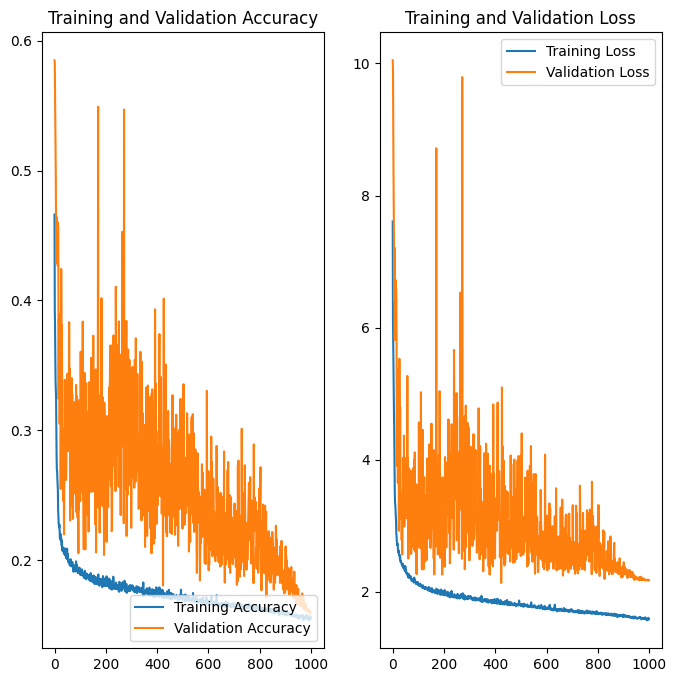

In [40]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(val_epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

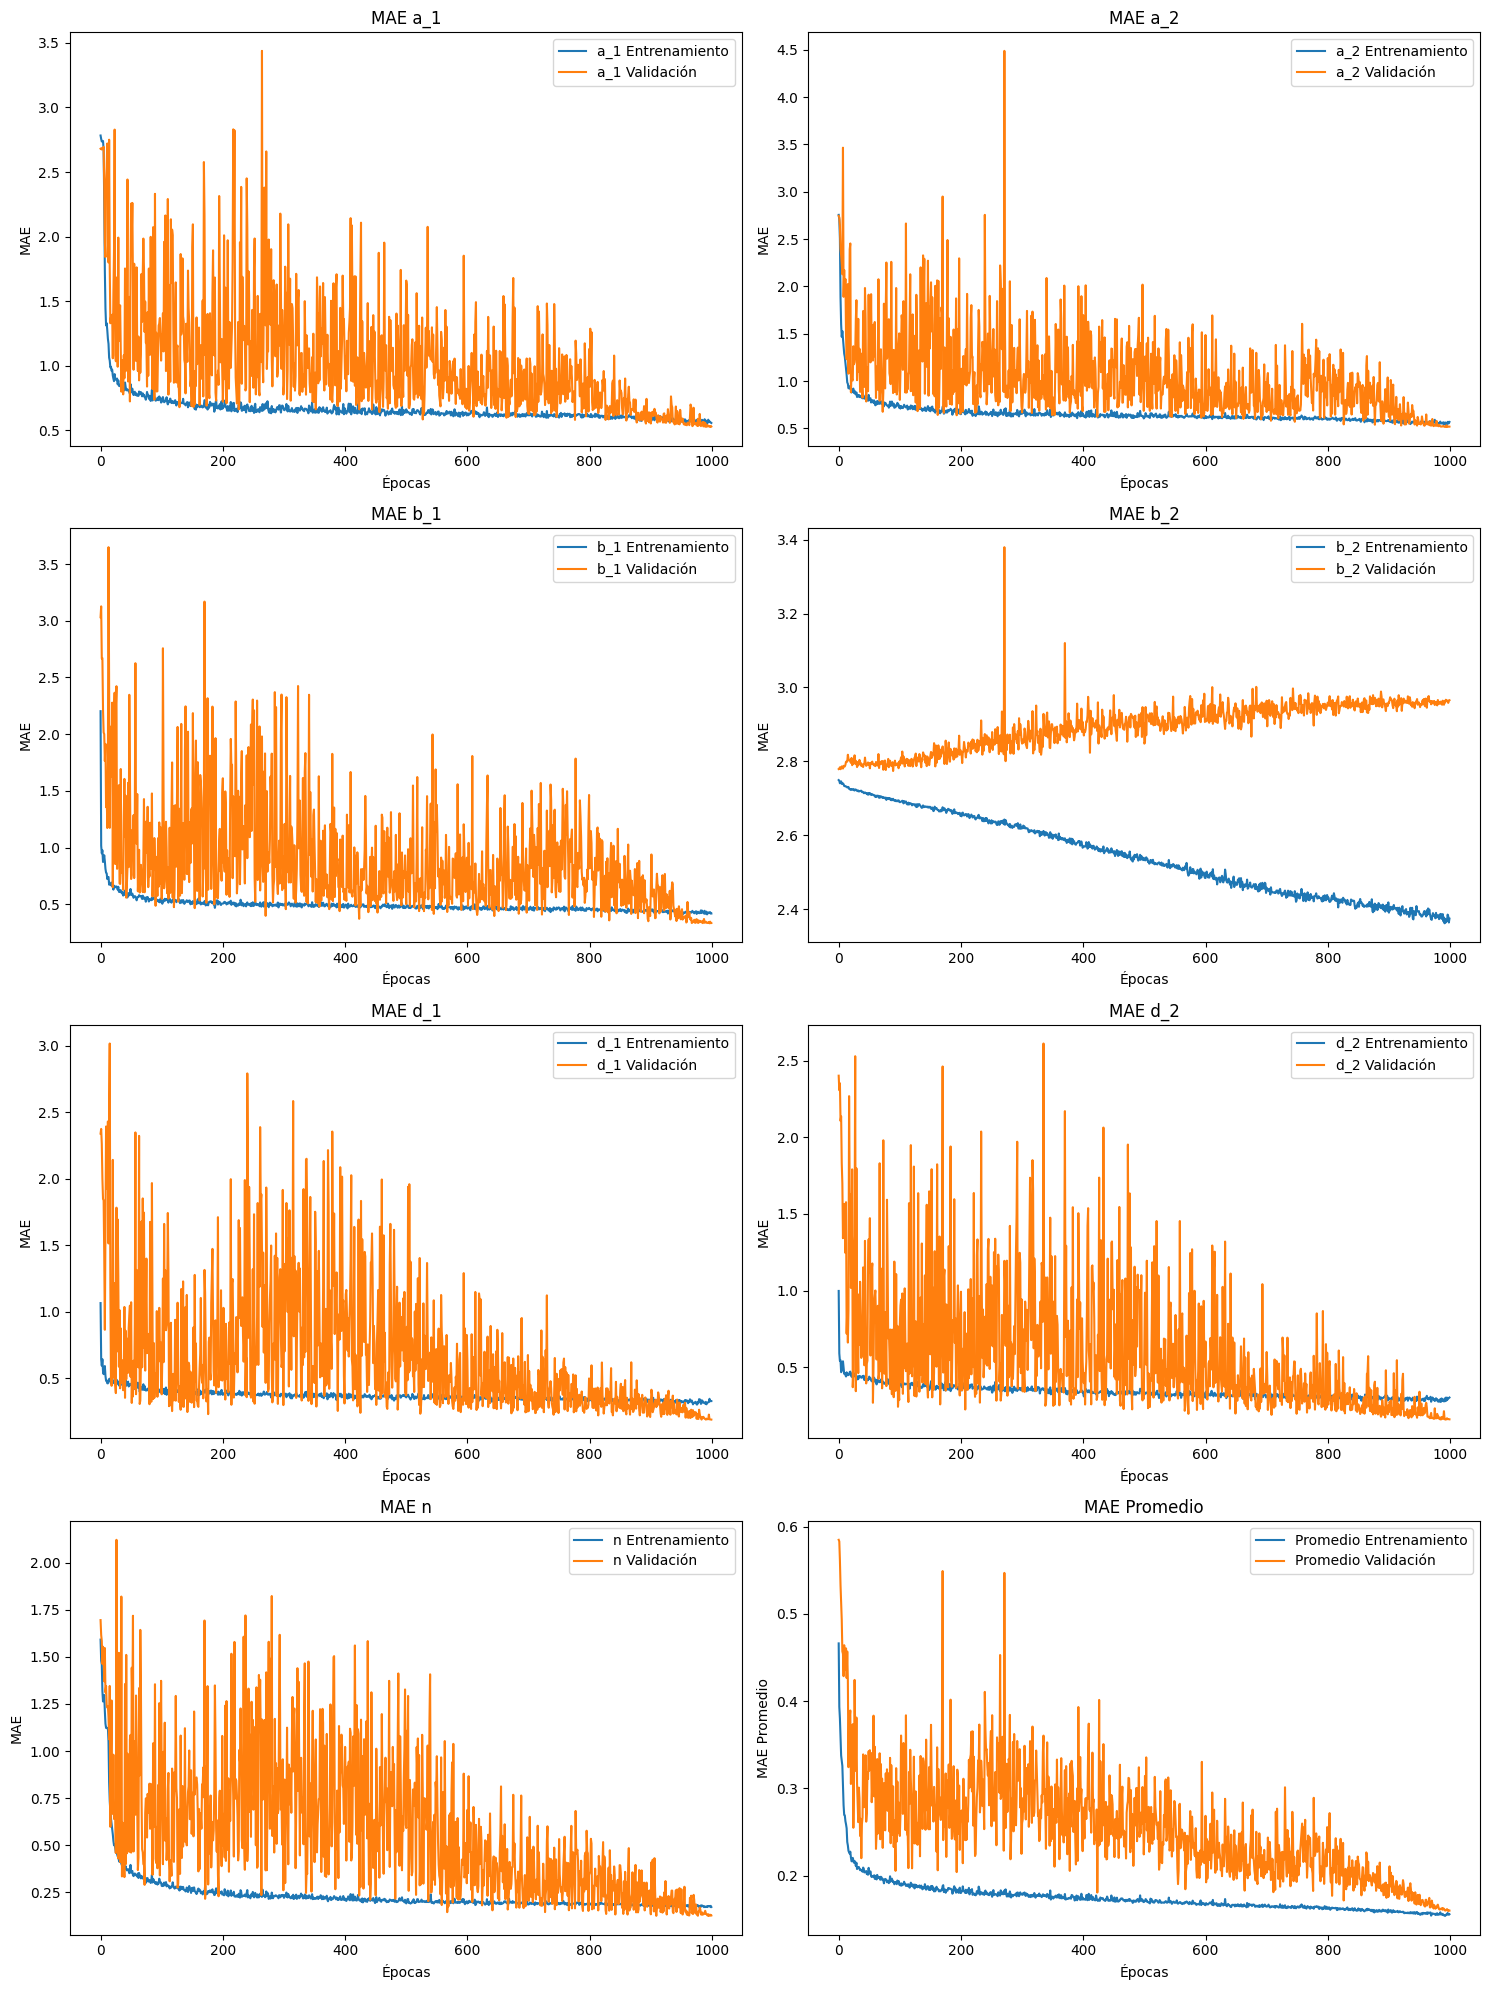

In [41]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [42]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

63/63 [==============================] - 0s 5ms/step - loss: 2.0743 - a_1: 0.5140 - a_2: 0.4914 - b_1: 0.3280 - b_2: 2.8608 - d_1: 0.1820 - d_2: 0.1642 - n: 0.1186 - mean_metric: 0.1551


In [43]:
predictions = model.predict(campvectest)

63/63 [==============================] - 0s 3ms/step


In [44]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[ 7 10  7  2  3  4  3]
[7.0900083 9.891745  6.8709664 6.977769  2.9518483 4.01689   3.259466 ]
[36 33 36 ... 37 24 39]


0.8042248317173549

In [45]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.6664776901451904, Desviación estándar del error: 1.3952869328422246, Error absoluto máximo: 8.262413144111633


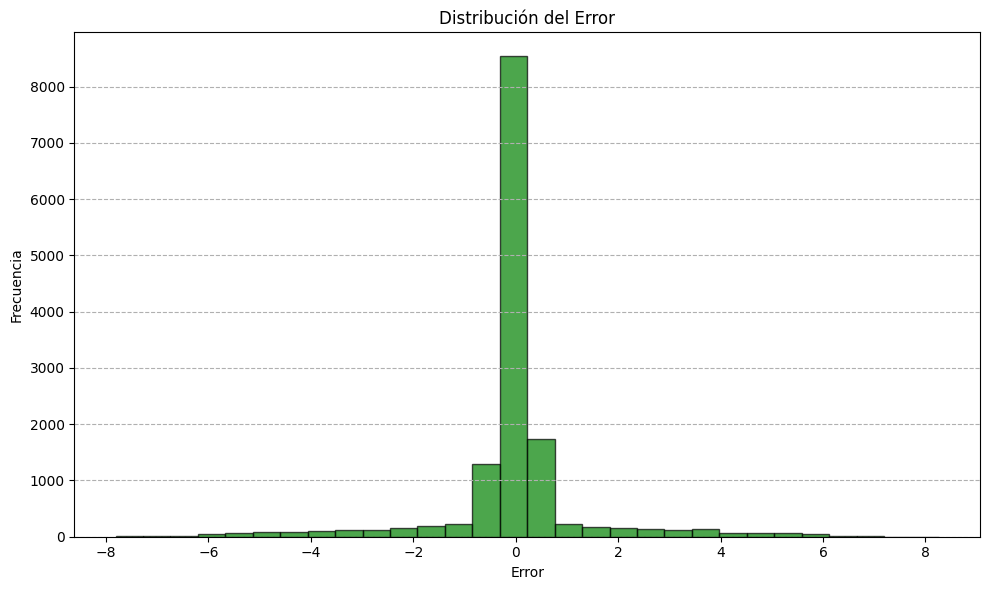

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [47]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.15881391378073437
Desviación estándar del error relativo: 0.13466244849406594
Error absoluto máximo relativo: 1.0622488734208875


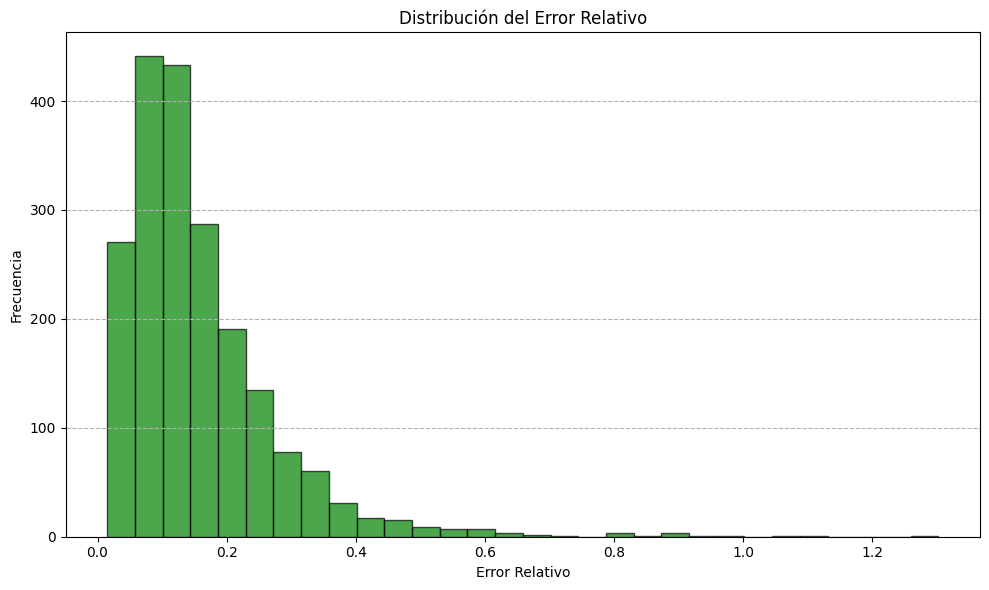

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()


# Guardamos los datos de Accuracy y Loss

In [49]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../histories/historyconvcampvec.csv', index=False)

# Guardamos el modelo

In [50]:
path_to_save = '../models'

In [51]:
model.save(path_to_save + '/convolucionalcv.h5')

# Importamos el modelo

In [1]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [2]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [3]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../models/convolucionalcv.h5', custom_objects=custom_objects)

C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.1
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [4]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos =10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[4, 2, 9, 7, 0, 7, 0]


In [5]:
campvecnone = campvec[None, :]
campvecnone = np.transpose(campvecnone, (0,2,3,1))

## Predecimos con los datos nuevos

In [6]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 156ms/step
[[ 0. 10. 10.  2.  2. 10.  0.]]


## Encontramos puntos de equilibro datos reales

In [7]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b1
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(-99.498743710662, 1.428571428574545)


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\optimize\_minpack_py.py:175: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

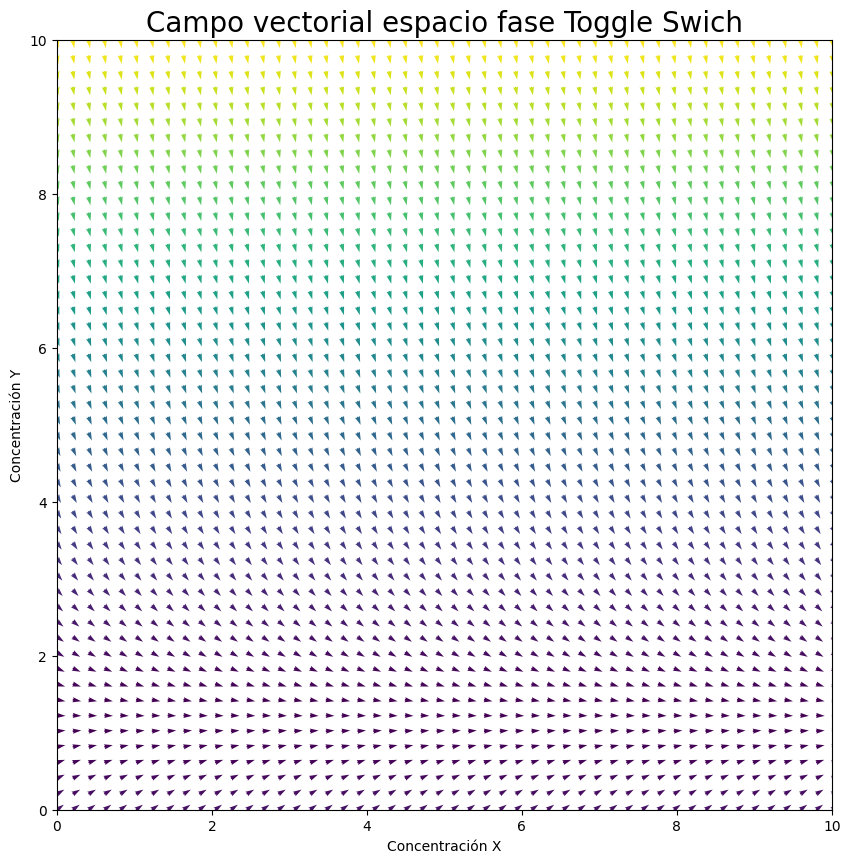

In [8]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 50)
y2 = np.linspace(0, 10, 50)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Encontramos puntos de equilibro datos predecidos

In [9]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b1pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(5.0, 1.5)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

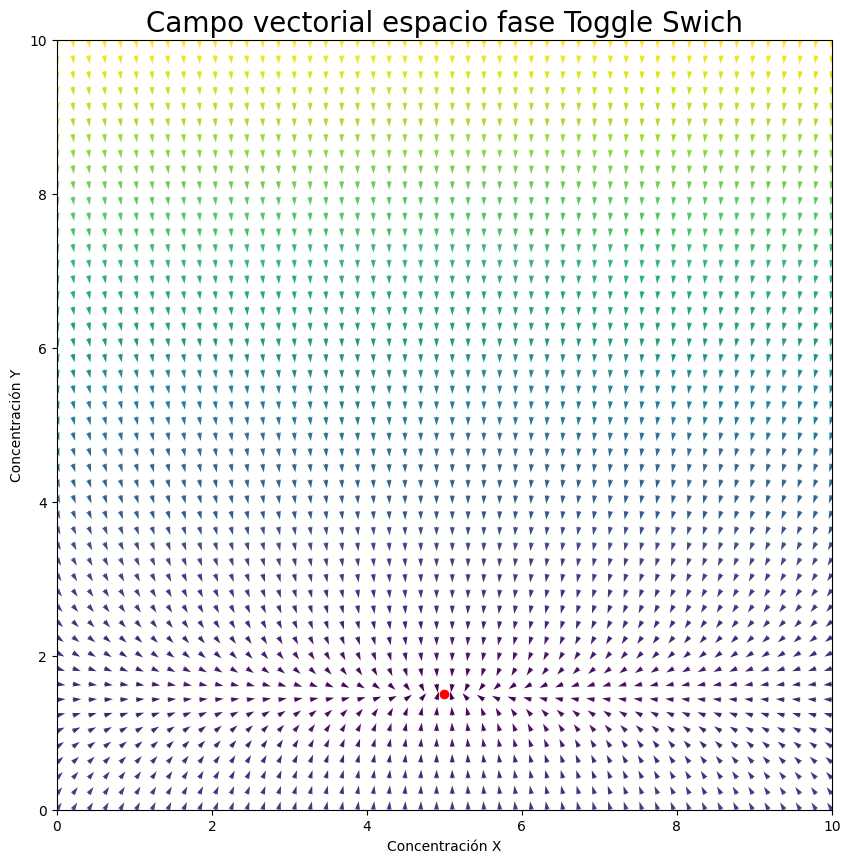

In [10]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b1pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 50)
y2pred = np.linspace(y_range_neg, y_range_pos, 50)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

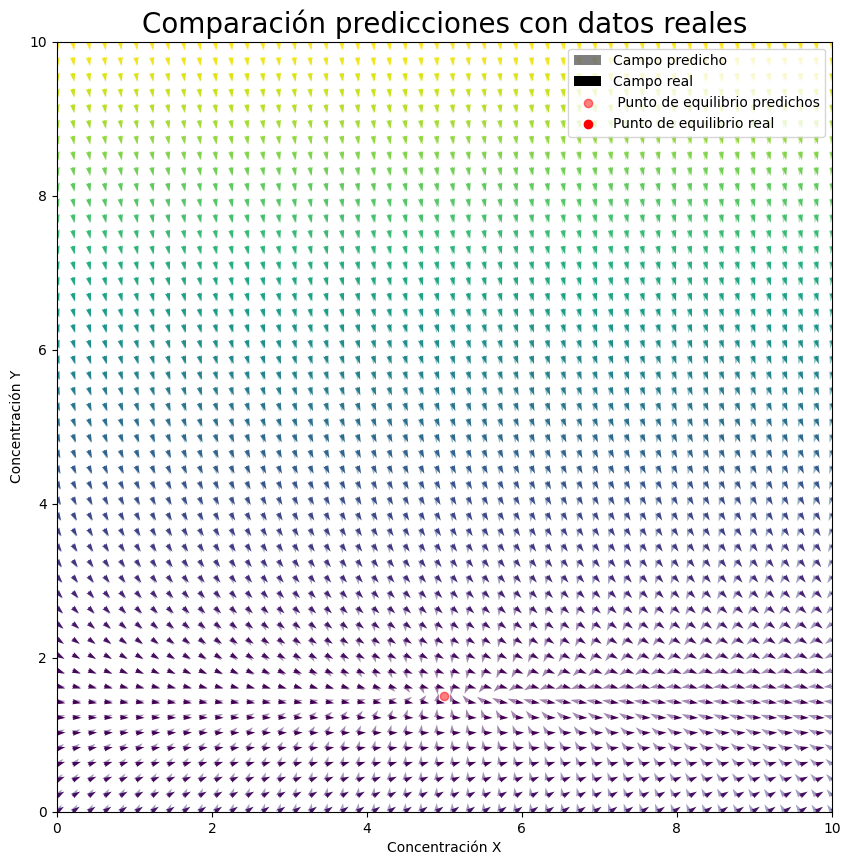

In [11]:
#%matplotlib qt
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5, label = "Campo predicho")

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1, label = "Campo real")

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5, label = " Punto de equilibrio predichos")
ax.scatter(x_values, y_values, color='red', alpha = 1, label = "Punto de equilibrio real")
ax.set_title('Comparación predicciones con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')
ax.legend(loc='upper right')  # Agregar leyenda a la gráfica
plt.show()

## Graficamos las diferencias

59.9407382407269


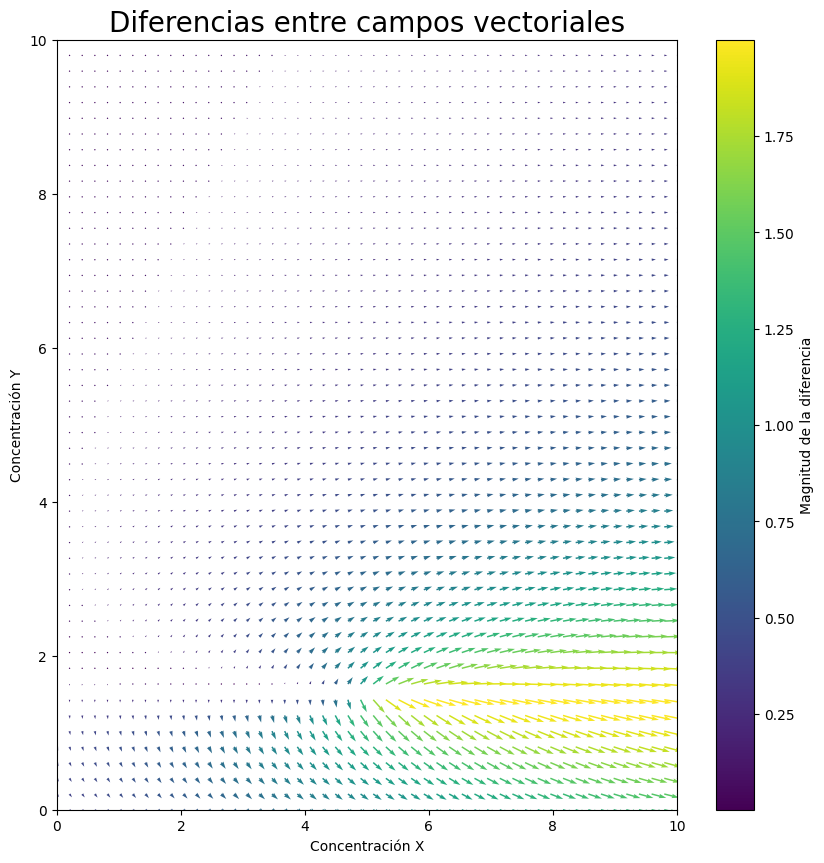

In [12]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

In [13]:
M_diff.mean()

0.5294542310026827

## Errores relativos

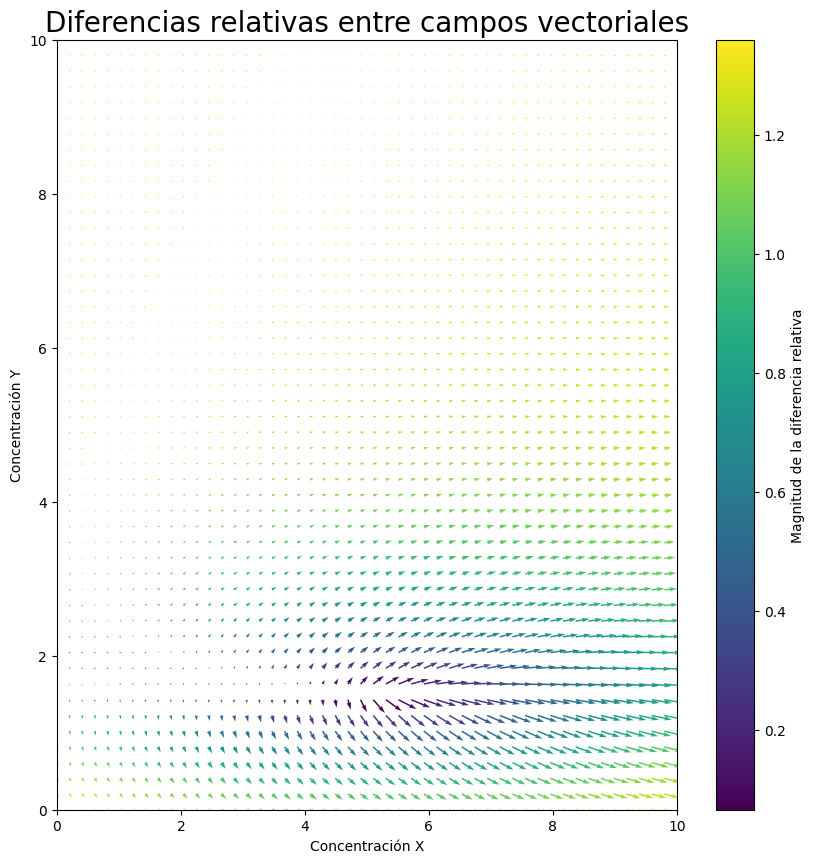

In [14]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [15]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 1.3591964075636744
El valor de u1 en el error relativo máximo es: 11.0
El valor de u1pred en el error relativo máximo es: 10.0
El valor de v1 en el error relativo máximo es: -62.0
El valor de v1pred en el error relativo máximo es: -85.0


In [16]:
np.sqrt(u1pred[max_coords]**2+v1pred[max_coords]**2)/np.sqrt(u1[max_coords]**2+v1[max_coords]**2)

1.3591964097222171

In [17]:
# Listas para almacenar los resultados
import random
porcentajes_por_dim = {}

for dim_size in range(40, 101, 5):
    porcentajes_temp = []  # Lista temporal para almacenar los porcentajes de cada iteración

    # Repetimos el proceso 10 veces
    for repetir in range(1000):
        campvec = []
        coef = []
        # constantes
        a1 = random.randint(0, 10)
        a2 = random.randint(0, 10)
        b1 = random.randint(0, 10)
        b2 = random.randint(0, 10)
        d1 = random.randint(0, 10)
        d2 = random.randint(0, 10)
        n = random.randint(0, 5)

        coef1 = [a1, a2, b1, b2, d1, d2, n]
        coef.append(coef1)

        def f(t, y):

            # asignar a cada ODE a un elemento de vector
            X = y[0]
            Y = y[1]

            # definimos cada ODE
            dX_dt = a1/(1+Y**n)-d1*X+b1
            dY_dt = a2/(1+X**n)-d2*Y+b2

            return [dX_dt, dY_dt]

        x_range_neg = 0
        x_range_pos = 10
        y_range_neg = 0
        y_range_pos = 10

        y1 = np.linspace(x_range_neg, x_range_pos, dim_size)
        y2 = np.linspace(y_range_neg, y_range_pos, dim_size)

        Y1, Y2 = np.meshgrid(y1, y2)
    
        t1 = 0

        u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

        NI, NJ = Y1.shape

        u1, v1 = f(t1, [Y1, Y2])
        u, v = f(t1, [Y1, Y2])
        M = (np.hypot(u, v))
        u /= M
        v /= M

        campvecci = np.append([u1], [v1], axis=0)

        campvec = campvecci
        print('--------------------------------------------')
    #    print(coef1)
    
        campvec = np.array(campvec)

    
        campvecnone = campvec[None, :]
        campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
        new_predictions = new_model.predict(campvecnone)
        new_predictions = np.round(new_predictions)
        new_predictions = np.clip(new_predictions, 0, None)
    #    print(new_predictions)
    
    
        a1pred = new_predictions[0,0]
        a2pred = new_predictions[0,1]
        b1pred = new_predictions[0,2]
        b2pred = new_predictions[0,3]
        d1pred = new_predictions[0,4]
        d2pred = new_predictions[0,5]
        npred = new_predictions[0,6]
    
        def f(t, y):

            # asignar a cada ODE a un elemento de vector
            X = y[0]
            Y = y[1]

            # definimos cada ODE
            dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
            dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

            return [dX_dt, dY_dt]

        x_range_neg = 0
        x_range_pos = 10
        y_range_neg = 0
        y_range_pos = 10

        y1pred = np.linspace(x_range_neg, x_range_pos, dim_size)
        y2pred = np.linspace(y_range_neg, y_range_pos, dim_size)
    
        Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
        t1 = 0

        upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)
    
        NI, NJ = Y1.shape

        u1pred, v1pred = f(t1, [Y1, Y2])
        upred, vpred = f(t1, [Y1, Y2])
        Mpred = (np.hypot(upred, vpred))
        upred /= Mpred
        vpred /= Mpred
    
     # Calculamos las diferencias
        u_diff = u - upred
        v_diff = v - vpred

        # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
        epsilon = 1e-7

        # Calculamos la magnitud del vector original y de la diferencia
        M_orig = np.hypot(u, v) + epsilon
        M_diff = np.hypot(u_diff, v_diff)

        # Calculamos la diferencia relativa
        M_diff_rel = M_diff / M_orig
    
        # Aplicamos el filtro para la diferencia relativa mayor a 0.05
        mask = M_diff_rel > 0.1

        # Calculamos el porcentaje de puntos que cumplen con la condición
        porcentaje = np.mean(mask) * 100

        # Almacenamos el resultado en la lista
        porcentajes_temp.append(porcentaje)

        print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")
    
    promedio = np.mean(porcentajes_temp)
    print(f"El porcentaje promedio de puntos cuyo error relativo es mayor a 0.05 con dimensión {dim_size} es {promedio:.2f}%")
    porcentajes_por_dim[dim_size] = promedio


--------------------------------------------
1/1 [==============================] - 0s 68ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 49.31%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 98.31%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 90.94%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 36.31%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 83.12%
--------------------------------------------
1/1 [=========================

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 97.31%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 95.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 80.31%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 83.62%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 57.19%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de p

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 97.88%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 84.50%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 53.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 94.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 40.25%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de p

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 83.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 65.06%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 98.12%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 98.88%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 68.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 85.94%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 70.94%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 99.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 22.19%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 30.06%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 97.25%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 100.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 99.06%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 7.88%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 49.88%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje

... (290 outputs left out)

1/1 [==============================] - 0s 17ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 861 es 92.98%
--------------------------------------------
1/1 [==============================] - 0s 17ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 862 es 19.22%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 863 es 3.65%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 864 es 56.60%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 865 es 8.89%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje d

1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 905 es 72.86%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 906 es 28.37%
--------------------------------------------
1/1 [==============================] - 0s 17ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 907 es 10.67%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 908 es 80.36%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 909 es 42.16%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje

1/1 [==============================] - 0s 17ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 949 es 15.17%
--------------------------------------------
1/1 [==============================] - 0s 17ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 950 es 10.95%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 951 es 69.74%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 952 es 85.02%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 953 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje 

1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 993 es 25.42%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 994 es 38.42%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 995 es 43.56%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 996 es 85.14%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 997 es 6.40%
--------------------------------------------
1/1 [==============================] - 0s 16ms/step
El porcentaje 

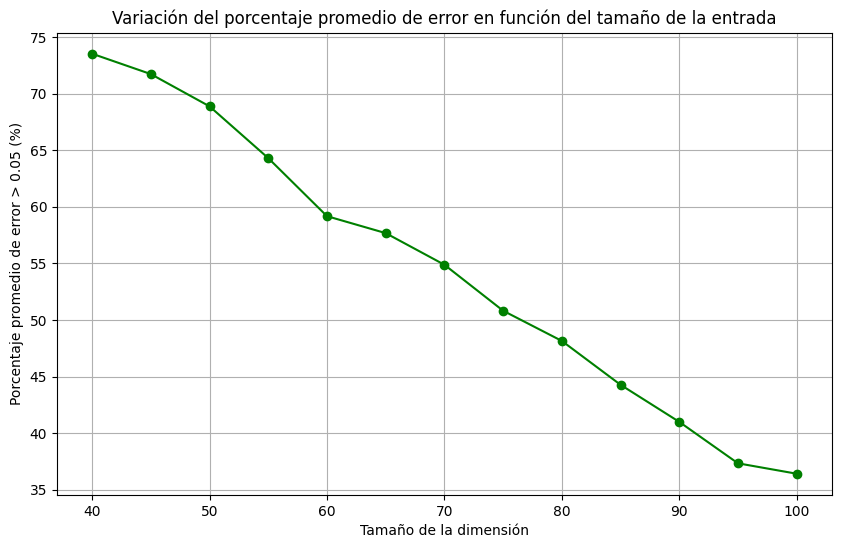

In [18]:
import matplotlib.pyplot as plt
# Graficar cómo varía la métrica promedio en función del tamaño de la entrada
plt.figure(figsize=(10, 6))
plt.plot(list(porcentajes_por_dim.keys()), list(porcentajes_por_dim.values()), marker='o', color = 'green')
plt.xlabel('Tamaño de la dimensión')
plt.ylabel('Porcentaje promedio de error > 0.05 (%)')
plt.title('Variación del porcentaje promedio de error en función del tamaño de la entrada')
plt.grid(True)
plt.show()